<a href="https://colab.research.google.com/github/OssamaSijbesma/uu-data-analysis-and-machine-learning-assignments/blob/main/assignment-2/report.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 2: Text clustering

Date: *15 october 2026*

Authors:
*   *Ossama Sijbesma (9890238)*
*   *Nóra Zala (8874905)*
*   *Rayana Sajith (9290184)*
*   *xxx*



In [ ]:
%pip install --quiet sentence_transformers wordcloud seaborn umap-learn

In [ ]:
# Import necessary libraries
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import umap
from nltk.stem import SnowballStemmer
from sentence_transformers import SentenceTransformer
from sklearn import decomposition
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    homogeneity_completeness_v_measure,
    normalized_mutual_info_score,
    silhouette_score,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer
from wordcloud import WordCloud

# Set global constants
RANDOM_SEED = 14
DATA_SOURCE = "https://raw.githubusercontent.com/OssamaSijbesma/uu-data-analysis-and-machine-learning-assignments/refs/heads/main/assignment-2/movie_review.csv"


In [ ]:
# Fetch dataset from github
raw_dataset = pd.read_csv(DATA_SOURCE)
raw_dataset.head()

,id,sentiment,review
0,5814_8,1,With all this stuff going down at the moment w...
1,2381_9,1,"\""The Classic War of the Worlds\"" by Timothy H..."
2,7759_3,0,The film starts with a manager (Nicholas Bell)...
3,3630_4,0,It must be assumed that those who praised this...
4,9495_8,1,Superbly trashy and wondrously unpretentious 8...


## Data description



In [ ]:
reviews = raw_dataset["review"].tolist()
split_words = raw_dataset["review"].str.split()

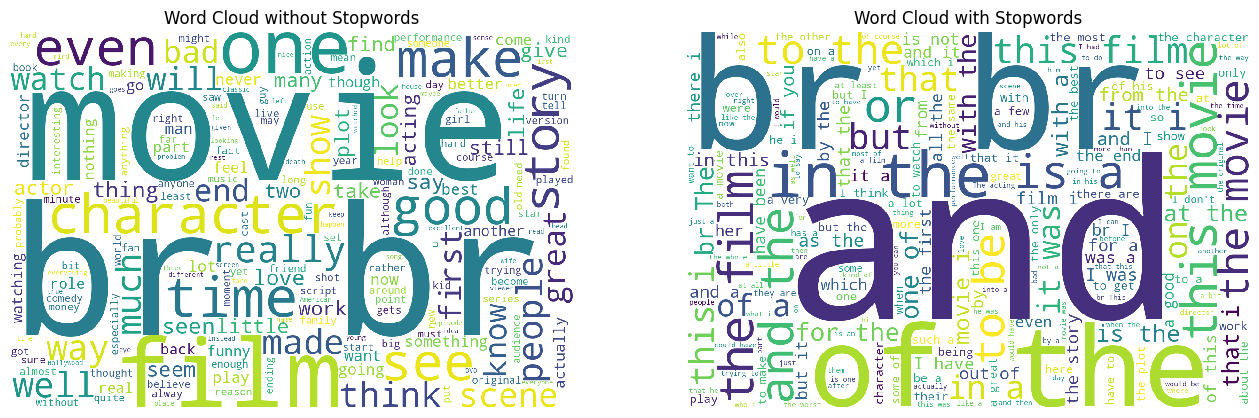

In [ ]:
# Create a word cloud with and without stopwords
all_reviews_text = " ".join(reviews)

wordcloud_with_stopwords = WordCloud(
    width=1200, height=800, background_color="white", stopwords=set()
).generate(all_reviews_text)

wordcloud = WordCloud(
    width=1200, height=800, background_color="white", stopwords=None
).generate(all_reviews_text)

plt.figure(figsize=(16, 8))

plt.subplot(1, 2, 1)
plt.imshow(wordcloud, interpolation="nearest")
plt.axis("off")
plt.title("Word Cloud without Stopwords")

plt.subplot(1, 2, 2)
plt.imshow(wordcloud_with_stopwords, interpolation="nearest")
plt.axis("off")
plt.title("Word Cloud with Stopwords")

plt.show()

Something about the difference and how br is still present in the word cloud without stopwords.

In [ ]:
# Min, Max, average, and total number of words in the reviews
word_counts = split_words.str.len()
min_words = word_counts.min()
max_words = word_counts.max()
average_words = int(word_counts.mean())
median_words = int(word_counts.median())
total_words = word_counts.sum()

print("Minimum number of words:", min_words)
print("Maximum number of words:", max_words)
print("Average number of words:", average_words)
print("Median number of words:", median_words)
print("Total number of words:", total_words)

Minimum number of words: 12
Maximum number of words: 2470
Average number of words: 237
Median number of words: 177
Total number of words: 1186896


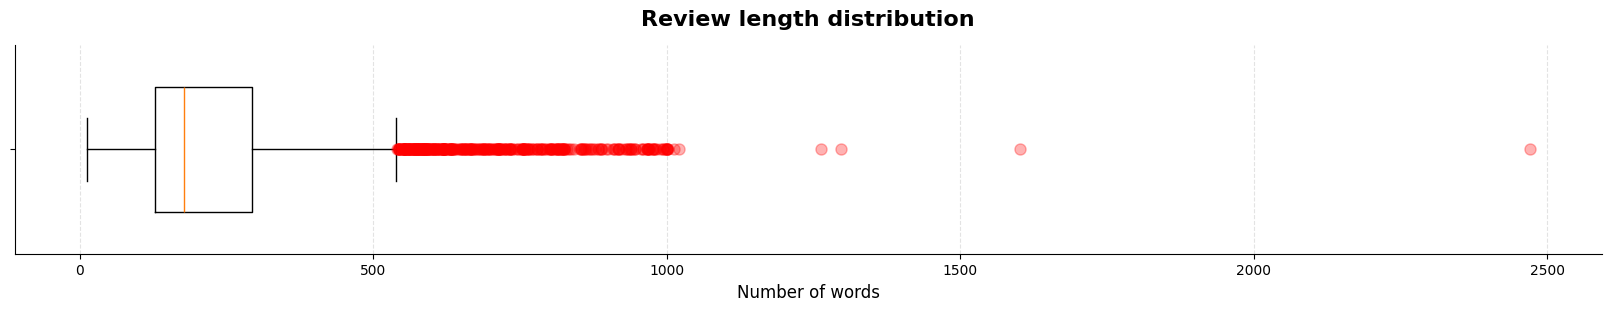

In [ ]:
# Box plot showing the distribution of review lengths in terms of word count
fig, ax = plt.subplots(figsize=(16, 3), constrained_layout=True)

box = ax.boxplot(
    word_counts,
    vert=False,
    widths=0.6,
    flierprops={
        "marker": "o",
        "markerfacecolor": "red",
        "markeredgecolor": "red",
        "alpha": 0.3,
        "markersize": 8,
    },
)

ax.set_title("Review length distribution", fontsize=16, weight="bold", pad=14)
ax.set_xlabel("Number of words", fontsize=12)
ax.set_yticklabels([""])
ax.set_axisbelow(True)
ax.xaxis.grid(True, linestyle="--", alpha=0.35)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [ ]:
# Check out the eight largest reviews
print("The eight largest reviews are:")
for review in sorted(reviews, key=lambda x: len(x.split()), reverse=True)[:8]:
    print(
        f"Review #{reviews.index(review) + 1} ({len(review.split())} words) - {review}"
    )

The eight largest reviews are:
Review #3486 (2470 words) - Match 1: Tag Team Table Match Bubba Ray and Spike Dudley vs Eddie Guerrero and Chris Benoit Bubba Ray and Spike Dudley started things off with a Tag Team Table Match against Eddie Guerrero and Chris Benoit. According to the rules of the match, both opponents have to go through tables in order to get the win. Benoit and Guerrero heated up early on by taking turns hammering first Spike and then Bubba Ray. A German suplex by Benoit to Bubba took the wind out of the Dudley brother. Spike tried to help his brother, but the referee restrained him while Benoit and Guerrero ganged up on him in the corner. With Benoit stomping away on Bubba, Guerrero set up a table outside. Spike dashed into the ring and somersaulted over the top rope onto Guerrero on the outside! After recovering and taking care of Spike, Guerrero slipped a table into the ring and helped the Wolverine set it up. The tandem then set up for a double superplex from the mi

In [ ]:
# Check out the eight shortest reviews
print("The eight shortest reviews are:")
for review in sorted(reviews, key=lambda x: len(x.split()))[:8]:
    print(
        f"Review #{reviews.index(review) + 1} ({len(review.split())} words) - {review}"
    )

The eight shortest reviews are:
Review #4049 (12 words) - Adrian Pasdar is excellent is this film. He makes a fascinating woman.
Review #3770 (19 words) - The characters are unlikeable and the script is awful. It's a waste of the talents of Deneuve and Auteuil.
Review #1203 (25 words) - Kept my attention from start to finish. Great performances added to this tremendous film. Mr. Pacino once again gives us another brilliant character to enjoy.
Review #2300 (25 words) - Much underrated camp movie on the level of Cobra Woman, etc. Photographic stills resemble Rembrandt prints. Sometimes subtle dialog and hidden literate touches found throughout.
Review #136 (26 words) - This is without a doubt the worst movie I have ever seen. It is not funny. It is not interesting and should not have been made.
Review #1185 (27 words) - Brilliant execution in displaying once and for all, this time in the venue of politics, of how \"good intentions do actually pave the road to hell\". Excellent!
Review #3

One outlier really jumps out from the rest. Looking at the review, it’s a detailed match-by-match report of WWE Vengeance 2002. While unusually long for a review, it still clearly acts as one therefore I’d classify it as a global outlier rather than a contextual outlier.

The next review is substantially shorter than our most extreme case, but it still stands out as a major outlier when looking at the rest of the data. It isn't until we reach the fifth review that the entries stop "feeling" like outliers. While all of these entries are legitimate reviews, their sheer size could cause issues later on with text representation methods and/or clustering methods.

On the other end of the distribution, the reviews are fairly standard, staying close to the mean and free of any foreseeable problems.

# Text pre-processing

Each review was passed through a custom preprocessing function before vectorization. The texts were lowercased so that differently capitalized forms of a word are counted as one feature. HTML line-break tags, which come from the website the reviews were scraped from, were removed because they would otherwise appear as a meaningless token “br”. Spoiler markers were removed since they are formatting rather than content, and escaped quote characters left over from the data export were converted back to plain quotes. Tokenization were handled by the vectorizer itself. These steps reduce noise and vocabulary size, which helps the clustering algorithm group reviews by their actual content.

In [ ]:
# Define stemmer
stemmer = SnowballStemmer("english")


# Define a custom text preprocessor for cleaning movie reviews
# It is used later in the text vectorization process
def custom_preprocessor(text):
    """Process and clean the input text."""
    # 1. Convert text to lowercase
    text = text.lower()
    # 2. Remove HTML tags (e.g., <br />)
    text = re.sub(r"<[^>]*>", "", text)
    # 3. Remove spoiler tags (e.g., [spoiler])
    text = re.sub(r"\[spoiler\]", "", text)
    # 4. Remove escape sequences (e.g. \\"the greatest filmed opera ever,\\")
    text = re.sub(r'\\"', '"', text)
    text = re.sub(r"\\'", "'", text)
    # 5. Stemming
    words = re.findall(r"[a-z']+", text)
    text = " ".join(stemmer.stem(w) for w in words)
    # Return cleaned text
    return text

In [ ]:
custom_preprocessor(reviews[8])

'a friend of mine bought this film for and even then it was grossli overpr despit featur big name such as adam sandler billi bob thornton and the incred talent burt young this film was about as funni as take a chisel and hammer it straight through your earhol it use tire bottom of the barrel comed techniqu consist break the fourth wall as sandler talk to the audienc and seem pointless montag of hot girl adam sandler play a waiter on a cruis ship who want to make it as a success comedian in order to becom success with women when the ship resid comedian the shameless name dicki due to his unfathom success with the opposit gender is presum lost at sea sandler charact shecker get his big break dicki is not dead he rather lock in the bathroom presum sea sick perhap from his mouth he just vomit the worst film of all time'

## Text representaion

To convert the reviews into numerical features we used TF-IDF, which represents each review as a vector whose entries reflect how important each term is to that review relative to the whole corpus. Unlike raw word counts, TF-IDF down-weights terms that occur in many reviews and highlights terms that distinguish one review from another, which is desirable for clustering. We considered sentence embeddings but they truncate long inputs and several reviews are far longer than the model’s limit, so we chose TF-IDF.

In [ ]:
# model = SentenceTransformer("all-MiniLM-L6-v2") # doesn't work with long texts
# embeddings = model.encode(raw_dataset["review"].tolist())

In [ ]:
# Instantiate vectorizer (automatically lowercases and handles basic stop words)
tfidf_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),  # Unigrams + Bigrams
    min_df=3,  # Ignore phrases appearing in fewer than 3 reviews
    max_df=0.80,  # Ignore corpus-wide words appearing in >80% of reviews (e.g., "movie", "film")
    stop_words="english",  # Remove stop words
    sublinear_tf=True,  # Apply 1 + log(tf) scaling to dampen word repetition in 3,000-word texts
    preprocessor=custom_preprocessor,  # Apply custom text cleaning before vectorization
)

# Learn vocabulary and transform corpus into sparse matrix
tfidf_matrix = tfidf_vectorizer.fit_transform(reviews)

# Extract feature names (vocabulary)
feature_names = tfidf_vectorizer.get_feature_names_out()

# Convert to Dense DataFrame for display
df_tfidf = pd.DataFrame(tfidf_matrix.toarray(), columns=feature_names)
print(df_tfidf)

/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:402: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['abov', 'afterward', 'alon', 'alreadi', 'alway', 'ani', 'anoth', 'anyon', 'anyth', 'anywher', 'becam', 'becaus', 'becom', 'befor', 'besid', 'cri', 'describ', 'dure', 'els', 'elsewher', 'empti', 'everi', 'everyon', 'everyth', 'everywher', 'fifti', 'forti', 'henc', 'hereaft', 'herebi', 'howev', 'hundr', 'inde', 'mani', 'meanwhil', 'moreov', 'nobodi', 'noon', 'noth', 'nowher', 'onc', 'onli', 'otherwis', 'ourselv', 'perhap', 'pleas', 'sever', 'sinc', 'sincer', 'sixti', 'someon', 'someth', 'sometim', 'somewher', 'themselv', 'thenc', 'thereaft', 'therebi', 'therefor', 'togeth', 'twelv', 'twenti', 'veri', 'whatev', 'whenc', 'whenev', 'wherea', 'whereaft', 'wherebi', 'wherev', 'whi', 'yourselv'] not in stop_words.
  warnings.warn(


      aag  aamir  aaron  abandon  abandon babi  abandon build  abbot  \
0     0.0    0.0    0.0      0.0           0.0            0.0    0.0   
1     0.0    0.0    0.0      0.0           0.0            0.0    0.0   
2     0.0    0.0    0.0      0.0           0.0            0.0    0.0   
3     0.0    0.0    0.0      0.0           0.0            0.0    0.0   
4     0.0    0.0    0.0      0.0           0.0            0.0    0.0   
...   ...    ...    ...      ...           ...            ...    ...   
4995  0.0    0.0    0.0      0.0           0.0            0.0    0.0   
4996  0.0    0.0    0.0      0.0           0.0            0.0    0.0   
4997  0.0    0.0    0.0      0.0           0.0            0.0    0.0   
4998  0.0    0.0    0.0      0.0           0.0            0.0    0.0   
4999  0.0    0.0    0.0      0.0           0.0            0.0    0.0   

      abbot costello  abbott  abbott costello  ...  zombi movi  zombi relat  \
0                0.0     0.0              0.0  ...      

In [ ]:
# Initialize UMAP for 2D projection
umap_2d = umap.UMAP(
    n_components=2,
    metric="cosine",
    n_neighbors=30,
    min_dist=0.0,
    random_state=RANDOM_SEED,
)

# Fit UMAP to the TF-IDF matrix and transform it into 2D points
points_2d = umap_2d.fit_transform(tfidf_matrix)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


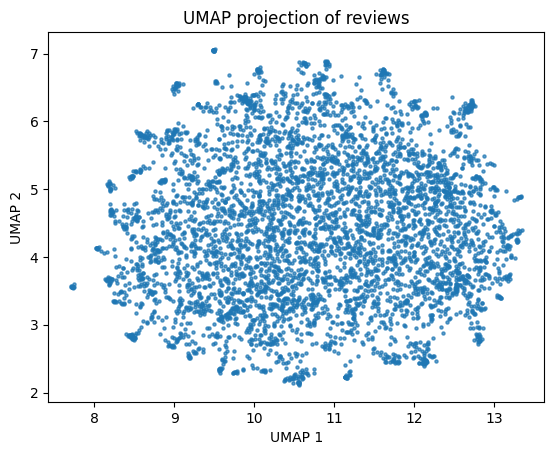

In [ ]:
# Plot UMAP points of the TF-IDF matrix
plt.scatter(points_2d[:, 0], points_2d[:, 1], s=5, alpha=0.7)
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.title("UMAP projection of reviews")
plt.show()

In [ ]:
def plot_cluster_grid(points_2d, labels, cols=5):
    """One panel per cluster: that cluster in red, all other reviews in grey."""
    cluster_ids = np.unique(labels)
    rows = int(np.ceil(len(cluster_ids) / cols))

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(4 * cols, 4 * rows),
        sharex=True,
        sharey=True,
        squeeze=False,
    )
    axes = axes.ravel()

    for ax, cluster_id in zip(axes, cluster_ids):
        in_cluster = labels == cluster_id
        # Grey background shows where the cluster sits relative to all reviews
        ax.scatter(*points_2d[~in_cluster].T, s=3, color="lightgrey", alpha=0.4)
        ax.scatter(*points_2d[in_cluster].T, s=6, color="tab:red", alpha=0.7)
        ax.set_title(f"Cluster {cluster_id} (n={in_cluster.sum()})")
        ax.set_xticks([])
        ax.set_yticks([])

    # Hide unused panels in the last row
    for ax in axes[len(cluster_ids) :]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


def plot_cluster_overview(points_2d, labels, title="Clusters of reviews"):
    """Single scatter plot with every cluster in its own colour and a density outline."""
    cluster_ids = np.unique(labels)
    colors = sns.color_palette("tab10", n_colors=len(cluster_ids))

    fig, ax = plt.subplots(figsize=(10, 7))

    for cluster_id, color in zip(cluster_ids, colors):
        x, y = points_2d[labels == cluster_id].T
        ax.scatter(x, y, color=color, s=10, alpha=0.3, label=f"Cluster {cluster_id}")

        # Outline the dense region of the cluster; skip tiny clusters where a KDE is unreliable
        if len(x) >= 30:
            sns.kdeplot(
                x=x, y=y, levels=1, thresh=0.40, color=color, linewidths=2, ax=ax
            )

    # Zoom in: limit the view to the 1st-99th percentile so a few outliers do not stretch the axes
    for set_lim, values in (
        (ax.set_xlim, points_2d[:, 0]),
        (ax.set_ylim, points_2d[:, 1]),
    ):
        low, high = np.percentile(values, [1, 99])
        margin = 0.20 * (high - low)
        set_lim(low - margin, high + margin)

    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")
    ax.set_title(title)
    ax.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()


def plot_clusters(points_2d, labels, title="Clusters of reviews"):
    """Plot a clustering in UMAP space: per-cluster grid plus an overview."""
    labels = np.asarray(labels)  # ensure boolean masks work for lists/Series
    plot_cluster_grid(points_2d, labels)
    plot_cluster_overview(points_2d, labels, title)

## Text clustering
K-means is a partitional clustering technique that divides data into k clusters based on feature similarity. The algorithm first assigns each point (review) to a cluster randomly, from which it calculates the centroid (the mean) of each cluster. Next, each point is assigned to the closest centroid point. Computing the centroid and reassignment of the points is done iteratively, until the points stop changing clusters and the grouping is stable.

In contrast to K-means, Ward is a hierarchical bottom-up clustering method. It works by first treating each data point as an individual cluster and it computes the within-cluster variance (measured by ESS) that would exist if two clusters were merged. Then, cluster pairs are merged in a way that the variance is minimized and this is repeated until the amount of specified clusters is reached (in this case 5 and 10).

Non-negative matrix factorization is a topic modeling technique that is suitable with the TF-IDF vectorization (opposed to e.g. Latent Dirichlet Allocation which models on raw word counts). This technique decomposes the TF-IDF matrix into two non-negative matrices, whose product is approximately the original TF-IDF matrix (V ≈ W x H). W is a review x topic matrix showing how strongly a review belongs to a topic, and H is a topic x word matrix wherein each row shows which words are included in a topic. Because all values are non-negative, each topic can only increase the weights of its associated words in a review’s reconstruction, never decrease them. Topics therefore combine additively, and each can be interpreted on its own through its top words.

### K-Means

In [ ]:
# Create KMeans clustering models for 5 and 10 clusters
k5means = KMeans(n_clusters=5, random_state=RANDOM_SEED, n_init=10)
k10means = KMeans(n_clusters=10, random_state=RANDOM_SEED, n_init=10)

# Label the documents with the cluster assignments
k5m_cluster_labels = k5means.fit_predict(tfidf_matrix)
k10m_cluster_labels = k10means.fit_predict(tfidf_matrix)

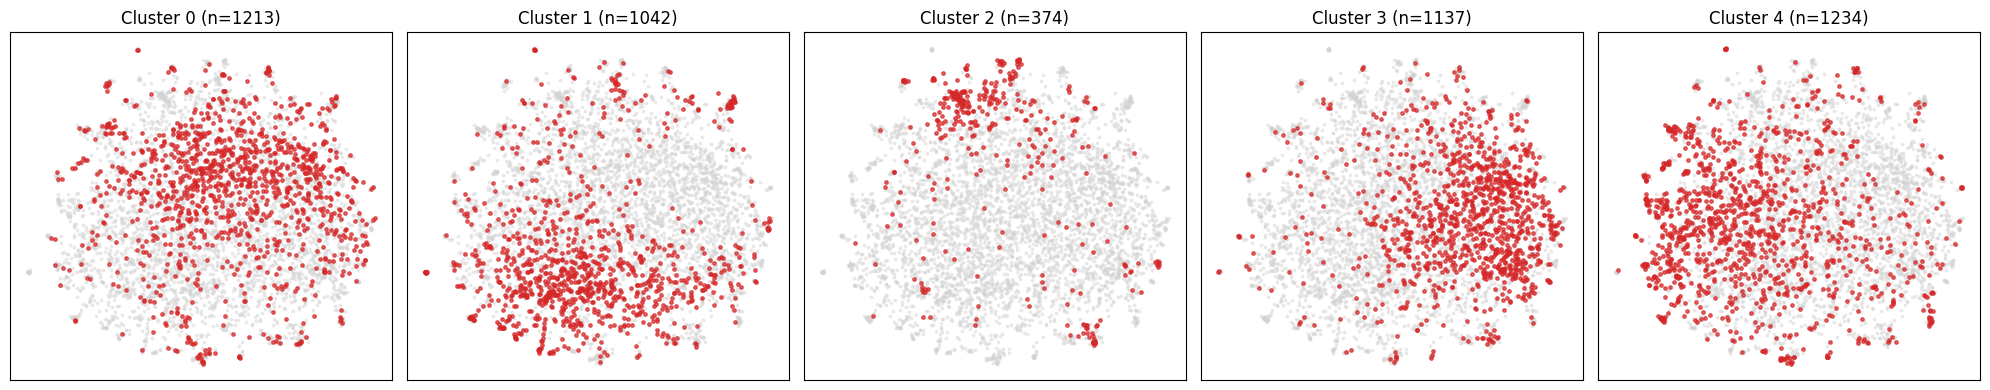

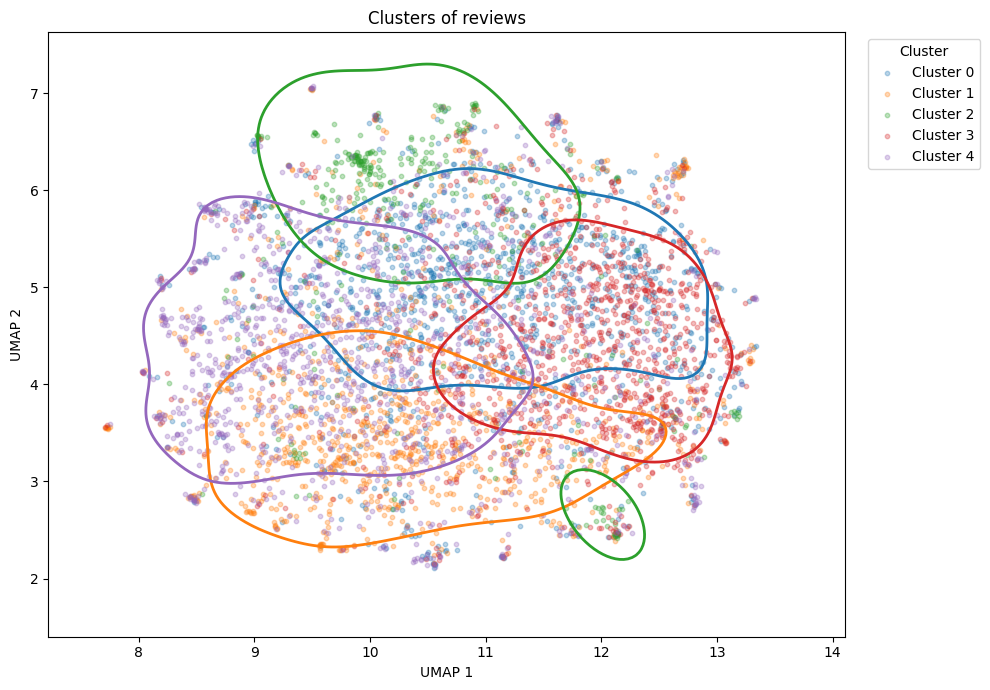

In [ ]:
plot_clusters(points_2d, k5m_cluster_labels)

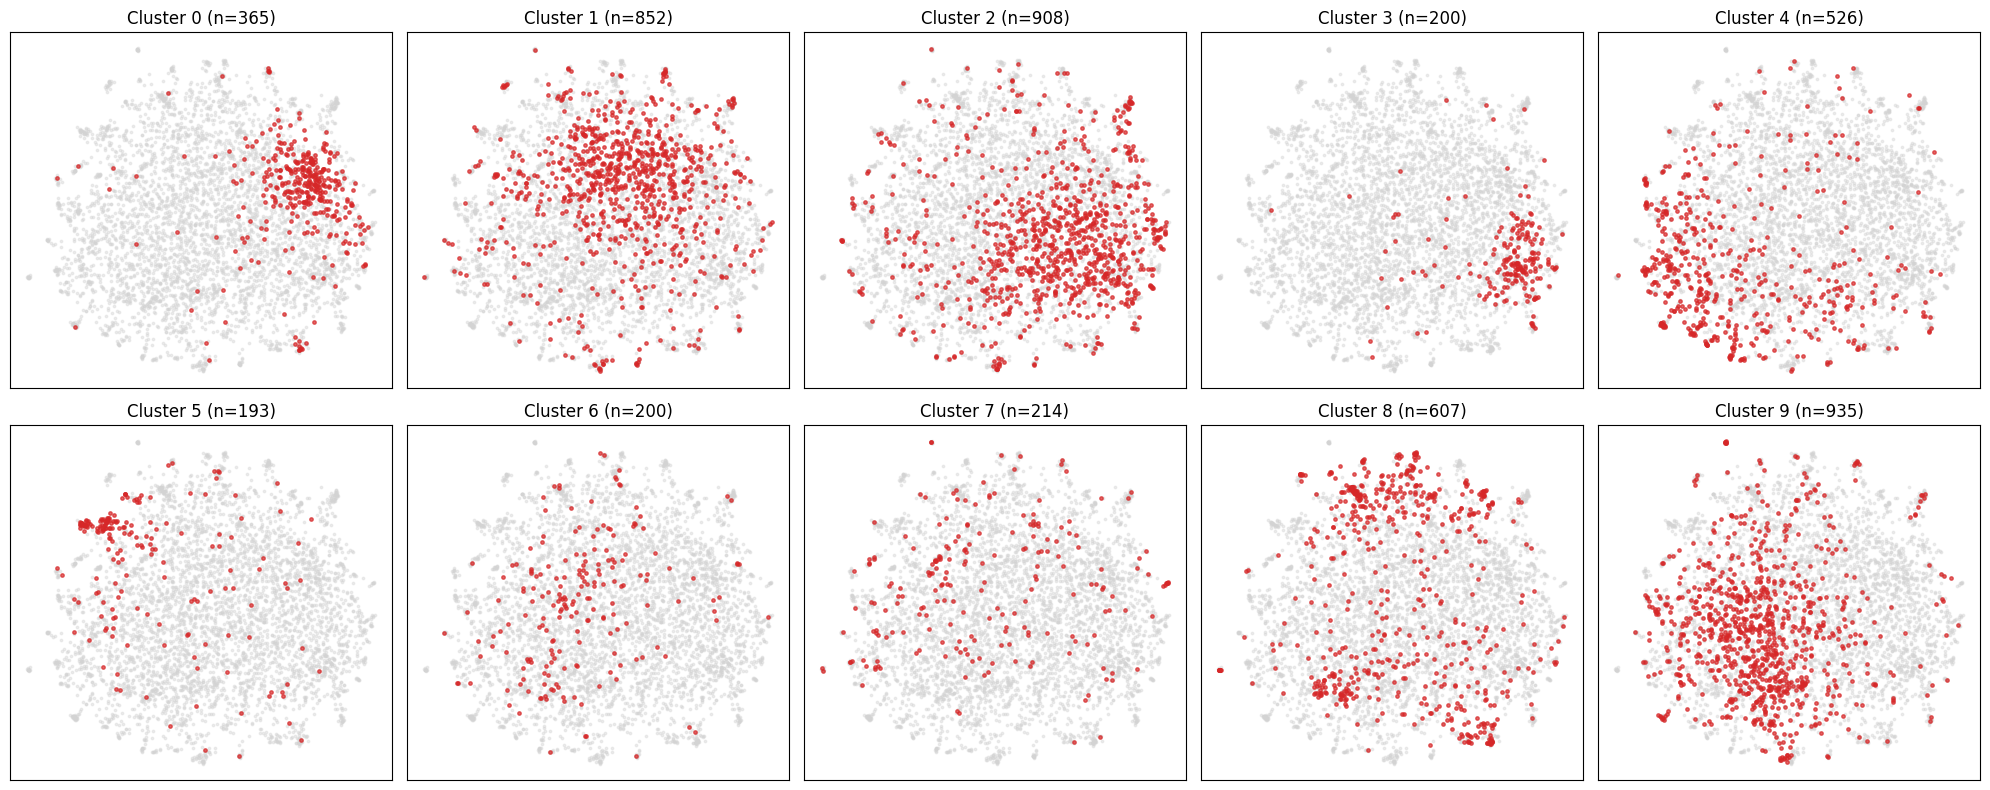

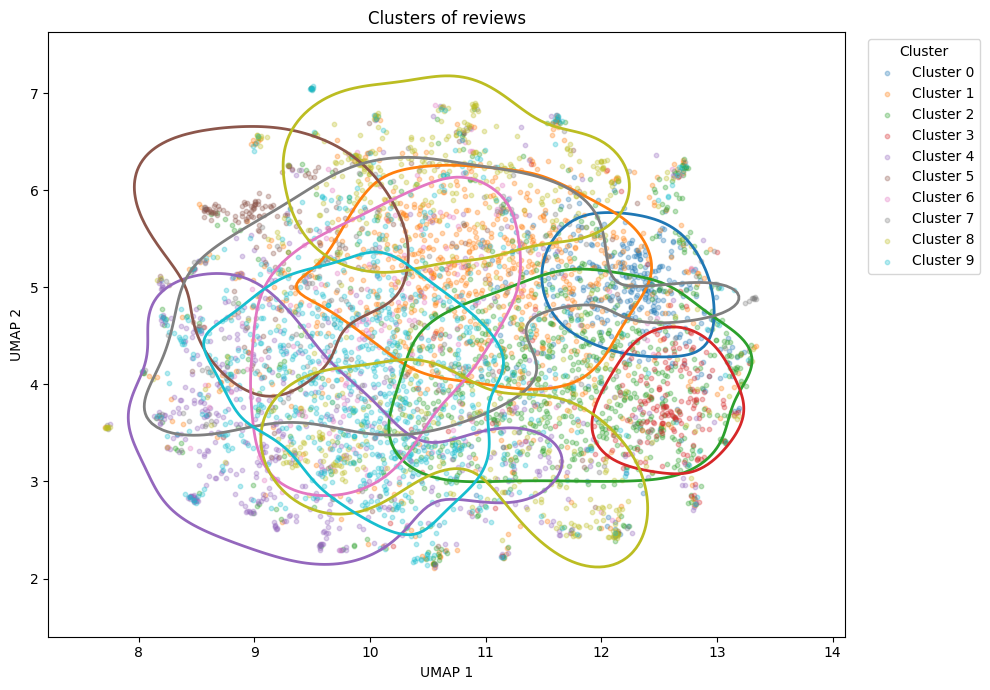

In [ ]:
plot_clusters(points_2d, k10m_cluster_labels)

In [ ]:
# Perform internal validation
k5_sil_score = silhouette_score(tfidf_matrix, k5m_cluster_labels)
k5_db_score = davies_bouldin_score(tfidf_matrix.toarray(), k5m_cluster_labels)
k5_ch_score = calinski_harabasz_score(tfidf_matrix.toarray(), k5m_cluster_labels)


# Perform internal validation for 10 clusters
k10_sil_score = silhouette_score(tfidf_matrix, k10m_cluster_labels)
k10_db_score = davies_bouldin_score(tfidf_matrix.toarray(), k10m_cluster_labels)
k10_ch_score = calinski_harabasz_score(tfidf_matrix.toarray(), k10m_cluster_labels)

# Print as pandas DataFrame
validation_df = pd.DataFrame(
    {
        "Clusters": ["5", "10"],
        "Silhouette": [k5_sil_score, k10_sil_score],
        "Davies-Bouldin": [k5_db_score, k10_db_score],
        "Calinski-Harabasz": [k5_ch_score, k10_ch_score],
    },
)

print(validation_df.to_string(index=False))

Clusters  Silhouette  Davies-Bouldin  Calinski-Harabasz
       5    0.000477       20.842554           5.552244
      10    0.000475       18.161907           3.785501


In [ ]:
sentiment = raw_dataset["sentiment"]

rows = []
for name, labels in {
    "K-means K=5": k5m_cluster_labels,
    "K-means K=10": k10m_cluster_labels,
}.items():
    homo, comp, v = homogeneity_completeness_v_measure(sentiment, labels)
    rows.append(
        {
            "Model": name,
            "ARI": adjusted_rand_score(sentiment, labels),
            "NMI": normalized_mutual_info_score(sentiment, labels),
            "Homogeneity": homo,
            "Completeness": comp,
            "V-measure": v,
        }
    )

print(pd.DataFrame(rows).round(4).to_string(index=False))

       Model    ARI    NMI  Homogeneity  Completeness  V-measure
 K-means K=5 0.0773 0.0839       0.1356        0.0608     0.0839
K-means K=10 0.0554 0.0814       0.1655        0.0539     0.0814


### Ward Agglomerative Clustering

In [ ]:
print(tfidf_matrix.shape)

(5000, 34457)


In [ ]:
tfidf_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.80,
    stop_words="english",
    sublinear_tf=True,
    preprocessor=custom_preprocessor,
)

tfidf_matrix = tfidf_vectorizer.fit_transform(reviews)
feature_names = tfidf_vectorizer.get_feature_names_out()

print(tfidf_matrix.shape)

/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:402: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['abov', 'afterward', 'alon', 'alreadi', 'alway', 'ani', 'anoth', 'anyon', 'anyth', 'anywher', 'becam', 'becaus', 'becom', 'befor', 'besid', 'cri', 'describ', 'dure', 'els', 'elsewher', 'empti', 'everi', 'everyon', 'everyth', 'everywher', 'fifti', 'forti', 'henc', 'hereaft', 'herebi', 'howev', 'hundr', 'inde', 'mani', 'meanwhil', 'moreov', 'nobodi', 'noon', 'noth', 'nowher', 'onc', 'onli', 'otherwis', 'ourselv', 'perhap', 'pleas', 'sever', 'sinc', 'sincer', 'sixti', 'someon', 'someth', 'sometim', 'somewher', 'themselv', 'thenc', 'thereaft', 'therebi', 'therefor', 'togeth', 'twelv', 'twenti', 'veri', 'whatev', 'whenc', 'whenev', 'wherea', 'whereaft', 'wherebi', 'wherev', 'whi', 'yourselv'] not in stop_words.
  warnings.warn(


(5000, 34457)


In [ ]:
import numpy as np
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

# Cosine similarity between all pairs of reviews
sim = (tfidf_matrix @ tfidf_matrix.T).toarray()
dist = np.sqrt(np.clip(2 - 2 * sim, 0, None))
np.fill_diagonal(dist, 0)  # distance from a review to itself is exactly 0

# Build the Ward merge tree ONCE from those distances.
Z = linkage(squareform(dist, checks=False), method="ward")

# Cut the same tree into 5 and 10 clusters.
ward5_labels = fcluster(Z, t=5, criterion="maxclust") - 1
ward10_labels = fcluster(Z, t=10, criterion="maxclust") - 1

print(pd.Series(ward5_labels).value_counts().sort_index())
print(pd.Series(ward10_labels).value_counts().sort_index())

# Cells 2 and 3 still need the dense table for Davies-Bouldin and Calinski-Harabasz
tfidf_dense = tfidf_matrix.toarray()

0      13
1    1821
2     483
3     328
4    2355
Name: count, dtype: int64
0      13
1      10
2       9
3    1802
4     194
5     289
6       8
7     320
8      16
9    2339
Name: count, dtype: int64


In [ ]:
cluster0_reviews = [r for r, lab in zip(reviews, ward5_labels) if lab == 0]

print(len(cluster0_reviews))
for r in cluster0_reviews[:3]:
    print(len(r.split()), "words:", r[:300])
    print("---")

13
118 words: This is, in my opinion, much better than either of the 2 1990's versions, but is still not all that good. It feels dated, probably because it is, but it does stand up well compared to other BBC 1980's period pieces such as Mansfield Park and Northanger Abbey.<br /><br />The length of this adaptation
---
60 words: In all the comments praising or damning Dalton's performance, I thought he was excellent. He does not play Rochester as a spoiled pretty rich boy, but as a roguish, powerful man. I liked this version, although the shot on video aspect was sometimes distracting, and the scenes with Jane and St. John 
---
543 words: Yes, this production is long (good news for Bronte fans!) and it has a somewhat dated feel, but both the casting and acting are so brilliant that you won't want to watch any other versions!<br /><br />Timothy Dalton IS Edward Rochester... it's that simple. I don't care that other reviewers claim he'
---


In [ ]:
# Internal validation
ward_scores = pd.DataFrame(
    {
        "Clusters": ["5", "10"],
        "Silhouette": [
            silhouette_score(tfidf_matrix, ward5_labels, metric="cosine"),
            silhouette_score(tfidf_matrix, ward10_labels, metric="cosine"),
        ],
        "Davies-Bouldin": [
            davies_bouldin_score(tfidf_dense, ward5_labels),
            davies_bouldin_score(tfidf_dense, ward10_labels),
        ],
        "Calinski-Harabasz": [
            calinski_harabasz_score(tfidf_dense, ward5_labels),
            calinski_harabasz_score(tfidf_dense, ward10_labels),
        ],
    }
)
print(ward_scores.round(3).to_string(index=False))



Clusters  Silhouette  Davies-Bouldin  Calinski-Harabasz
       5      -0.002          23.256              3.318
      10      -0.005          14.243              3.023


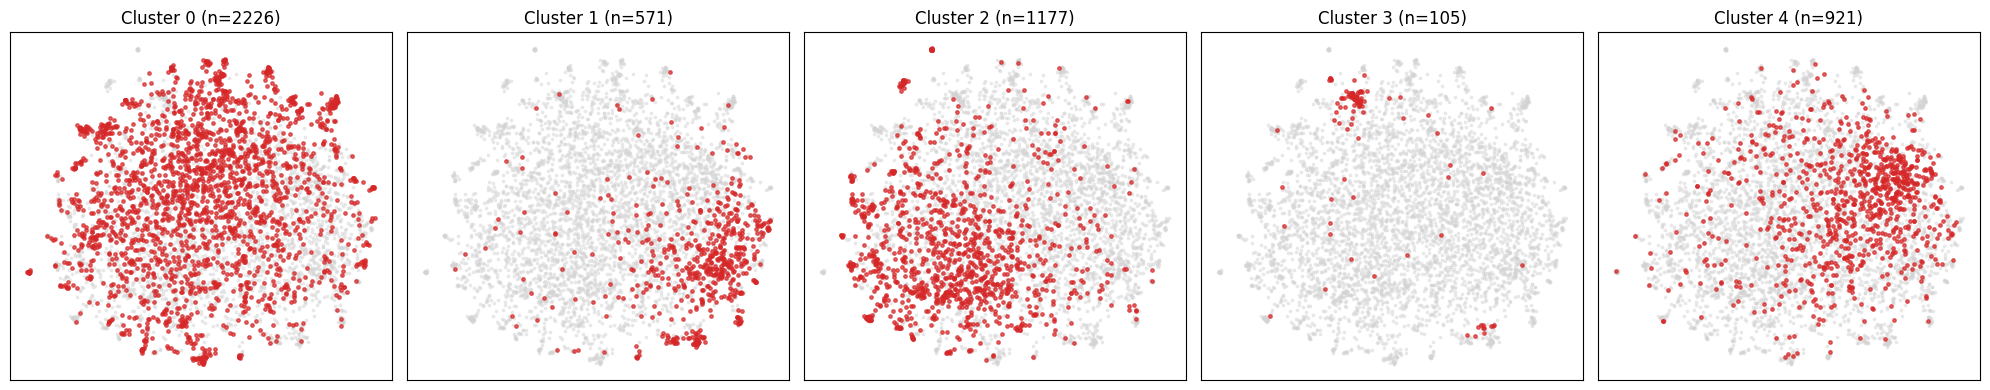

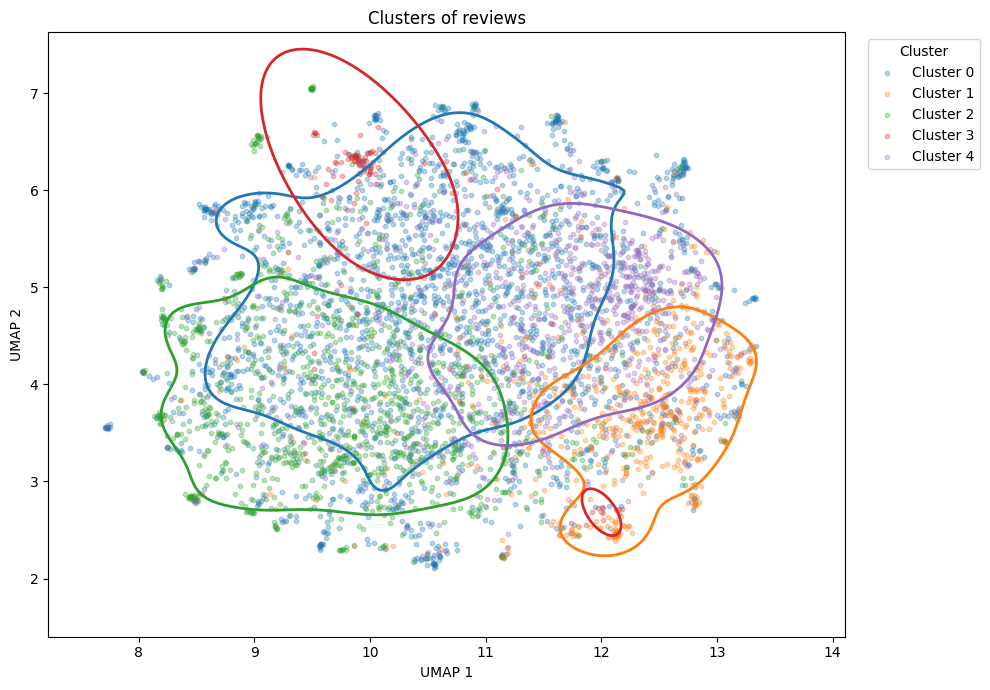

In [ ]:
plot_clusters(points_2d, ward5_labels)

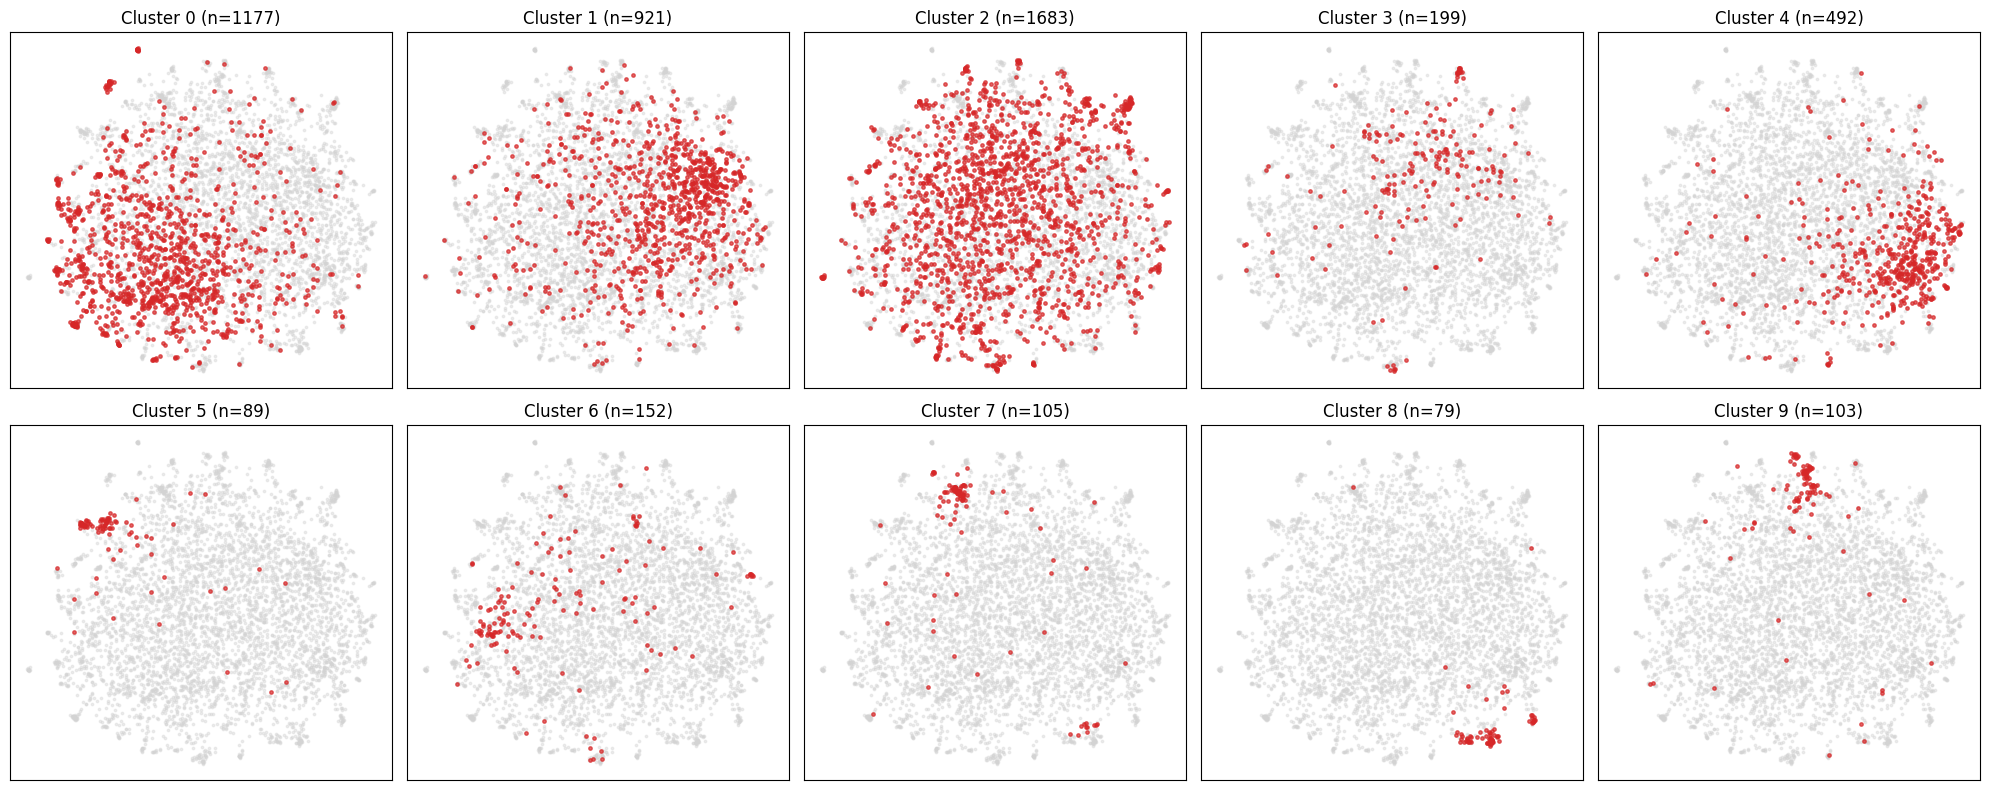

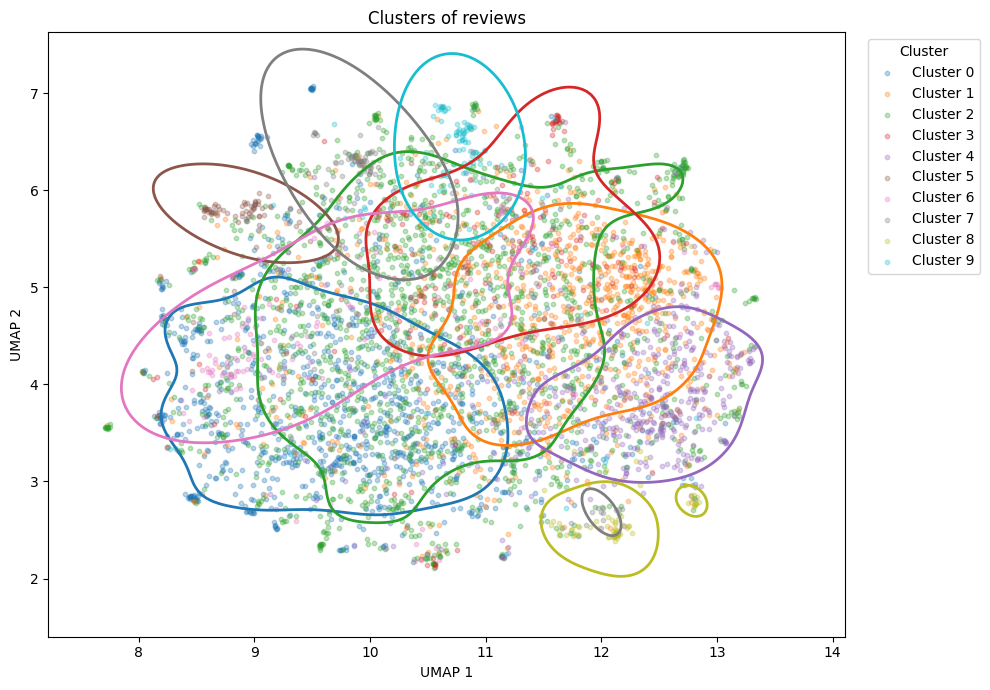

In [ ]:
plot_clusters(points_2d, ward10_labels)

In [ ]:
# External validation against sentiment
true = raw_dataset["sentiment"]
h5, c5, v5 = homogeneity_completeness_v_measure(true, ward5_labels)
h10, c10, v10 = homogeneity_completeness_v_measure(true, ward10_labels)

ward_ext = pd.DataFrame(
    {
        "Clusters": ["5", "10"],
        "Adjusted Rand Index": [adjusted_rand_score(true, ward5_labels), adjusted_rand_score(true, ward10_labels)],
        "Normalized Mutual Information": [normalized_mutual_info_score(true, ward5_labels), normalized_mutual_info_score(true, ward10_labels)],
        "Homogeneity": [h5, h10],
        "Completeness": [c5, c10],
        "V_Measure": [v5, v10],
    }
)
print(ward_ext.round(3).to_string(index=False))

Clusters  Adjusted Rand Index  Normalized Mutual Information  Homogeneity  Completeness  V_Measure
       5                0.020                          0.033        0.044         0.027      0.033
      10                0.016                          0.038        0.053         0.029      0.038


### Topic Modeling: Non-negative Matrix Factorization (NMF)

In [ ]:
# Define NMF decomposition models for 5 and 10 topics
nmf_5 = decomposition.NMF(n_components=5, random_state=111)
nmf_10 = decomposition.NMF(n_components=10, random_state=111)

# Take W and H from these decompositions
W_5 = nmf_5.fit_transform(tfidf_matrix)
H_5 = nmf_5.components_
W_10 = nmf_10.fit_transform(tfidf_matrix)
H_10 = nmf_10.components_

/usr/local/lib/python3.13/dist-packages/sklearn/decomposition/_nmf.py:1742: ConvergenceWarning: Maximum number of iterations 200 reached. Increase it to improve convergence.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/decomposition/_nmf.py:1742: ConvergenceWarning: Maximum number of iterations 200 reached. Increase it to improve convergence.
  warnings.warn(


In [ ]:
# matrix storing the weights of each word contributing to each topic
print(f"matrix dimensions: {len(H_5)}x{len(H_5[0])}")
print()

matrix dimensions: 5x34457



In [ ]:
# matrix storing how strongly each review is associated with each topic
print(f"matrix dimensions: {len(W_5)}x{len(W_5[0])}")
print(W_5)

matrix dimensions: 5000x5
[[0.02098492 0.04659145 0.04046413 0.00529628 0.02914561]
 [0.03525442 0.00501098 0.03117168 0.02941007 0.        ]
 [0.00225569 0.00702643 0.         0.05010698 0.06654935]
 ...
 [0.         0.05191009 0.         0.008484   0.04189548]
 [0.         0.         0.00753648 0.06038622 0.00358916]
 [0.00975777 0.02856073 0.00642312 0.00884108 0.0375421 ]]


In [ ]:
n_words = 15

# Extract feature names
words = np.array(tfidf_vectorizer.get_feature_names_out())

# Take the top 15 words for each topic, put them in one str and separate topics in a list
top_words = lambda t: [words[i] for i in np.argsort(t)[: -n_words - 1 : -1]]
topic_words_5 = [top_words(t) for t in H_5]
topics_5 = [" ".join(t) for t in topic_words_5]

topic_words_10 = [top_words(t) for t in H_10]
topics_10 = [" ".join(t) for t in topic_words_10]

In [ ]:
topics_5

['film life peopl stori charact way feel mani war world real live make american ani',
 'bad movi act film worst plot wast just make aw don onli like terribl look',
 'movi watch like realli think good great just love veri don time enjoy funni watch movi',
 'film perform play role cast best actor great good veri charact excel act direct star',
 'kill man old hous run look girl start like year end littl guy just dead']

In [ ]:
topics_10

['life charact stori peopl war world way american mani real feel work human ani live',
 'bad movi worst wast act don just plot aw terribl wast time whi make money like',
 'movi great good watch realli veri like think love stori watch movi just don thought recommend',
 'perform play role cast actor best great direct star excel charact support good act lead',
 'old year man girl famili kill father live want boy friend young guy end woman',
 'book read version read book novel adapt jane rochest eyr jane eyr dalton year timothi timothi dalton mr',
 'episod seri anim season tv origin watch like charact fan best just cartoon televis realli',
 'horror effect budget low special horror movi special effect low budget gore scene zombi horror film look good pretti',
 'film watch realli enjoy watch film saw seen veri end make onli like say think film make',
 'funni comedi laugh joke humor hilari funniest fun eddi veri funni moment gag time old scene']

In [ ]:
# Name each row and column
col_names_5 = ["Topic " + str(i) for i in range(nmf_5.n_components)]
col_names_10 = ["Topic " + str(i) for i in range(nmf_10.n_components)]
review_names = ["Review " + str(i) for i in range(len(reviews))]

# Create data frames that shows how strongly a review belongs to a topic
df_review_topic_5 = pd.DataFrame(
    np.round(W_5, 2), columns=col_names_5, index=review_names
)
df_review_topic_10 = pd.DataFrame(
    np.round(W_10, 2), columns=col_names_10, index=review_names
)

# Create a column that indicates which topic the review belongs to most
dominant_topic_5 = np.argmax(df_review_topic_5.values, axis=1)
dominant_topic_10 = np.argmax(df_review_topic_10.values, axis=1)
df_review_topic_5["dominant_topic"] = dominant_topic_5
df_review_topic_10["dominant_topic"] = dominant_topic_10

In [ ]:
df_review_topic_5

,Topic 0,Topic 1,Topic 2,Topic 3,Topic 4,dominant_topic
Review 0,0.02,0.05,0.04,0.01,0.03,1
Review 1,0.04,0.01,0.03,0.03,0.00,0
Review 2,0.00,0.01,0.00,0.05,0.07,4
Review 3,0.04,0.02,0.01,0.04,0.00,0
Review 4,0.02,0.01,0.01,0.02,0.06,4
...,...,...,...,...,...,...
Review 4995,0.02,0.06,0.00,0.04,0.00,1
Review 4996,0.00,0.02,0.00,0.05,0.01,3
Review 4997,0.00,0.05,0.00,0.01,0.04,1
Review 4998,0.00,0.00,0.01,0.06,0.00,3


In [ ]:
df_review_topic_10

,Topic 0,Topic 1,Topic 2,Topic 3,Topic 4,Topic 5,Topic 6,Topic 7,Topic 8,Topic 9,dominant_topic
Review 0,0.01,0.05,0.03,0.00,0.03,0.00,0.02,0.01,0.03,0.00,1
Review 1,0.02,0.00,0.02,0.00,0.00,0.10,0.00,0.00,0.03,0.01,5
Review 2,0.01,0.00,0.00,0.05,0.02,0.00,0.02,0.07,0.00,0.00,7
Review 3,0.03,0.02,0.01,0.03,0.00,0.02,0.00,0.00,0.03,0.00,0
Review 4,0.02,0.01,0.00,0.02,0.05,0.00,0.00,0.02,0.00,0.01,4
...,...,...,...,...,...,...,...,...,...,...,...
Review 4995,0.01,0.04,0.00,0.03,0.01,0.00,0.00,0.01,0.04,0.06,9
Review 4996,0.00,0.02,0.00,0.04,0.00,0.02,0.07,0.00,0.00,0.00,6
Review 4997,0.00,0.06,0.00,0.02,0.03,0.00,0.00,0.02,0.00,0.00,1
Review 4998,0.00,0.00,0.01,0.06,0.00,0.04,0.00,0.00,0.00,0.00,3


In [ ]:
# To do a sanity check, compare a review to its corresponding topic words
print(f"Review: {reviews[1202]}")  # chose one of the shortest ones to simplify check
print(
    f"Topic with 5 topic model: {topics_5[df_review_topic_5.loc['Review 1202', 'dominant_topic']]}"
)
print(
    f"Topic with 10 topic model: {topics_10[df_review_topic_10.loc['Review 1202', 'dominant_topic']]}"
)

Review: Kept my attention from start to finish. Great performances added to this tremendous film. Mr. Pacino once again gives us another brilliant character to enjoy.
Topic with 5 topic model: film perform play role cast best actor great good veri charact excel act direct star
Topic with 10 topic model: perform play role cast actor best great direct star excel charact support good act lead


Based on the check above, there are some generic words in the topics (e.g. film) that do not tell us much about the sentiment or the topic. But overall, this topic for both models seem to emphasize a positive sentiment about the acting and directing which agrees with this review example.

In [ ]:
# Internal validation
nmf_5_sil_score = silhouette_score(
    tfidf_matrix, df_review_topic_5.loc[:, "dominant_topic"], metric="cosine"
)
nmf_5_db_score = davies_bouldin_score(
    tfidf_matrix.toarray(), df_review_topic_5.loc[:, "dominant_topic"]
)
nmf_5_ch_score = calinski_harabasz_score(
    tfidf_matrix.toarray(), df_review_topic_5.loc[:, "dominant_topic"]
)


# Perform internal validation for 10 clusters
nmf_10_sil_score = silhouette_score(
    tfidf_matrix, df_review_topic_10.loc[:, "dominant_topic"], metric="cosine"
)
nmf_10_db_score = davies_bouldin_score(
    tfidf_matrix.toarray(), df_review_topic_10.loc[:, "dominant_topic"]
)
nmf_10_ch_score = calinski_harabasz_score(
    tfidf_matrix.toarray(), df_review_topic_10.loc[:, "dominant_topic"]
)

# Print as pandas DataFrame
int_val_df_nmf = pd.DataFrame(
    {
        "Clusters": ["5", "10"],
        "Silhouette": [nmf_5_sil_score, nmf_10_sil_score],
        "Davies-Bouldin": [nmf_5_db_score, nmf_10_db_score],
        "Calinski-Harabasz": [nmf_5_ch_score, nmf_10_ch_score],
    },
)

print(int_val_df_nmf.to_string(index=False))

Clusters  Silhouette  Davies-Bouldin  Calinski-Harabasz
       5    0.001904       21.100574           5.253899
      10    0.002328       16.844802           4.203381


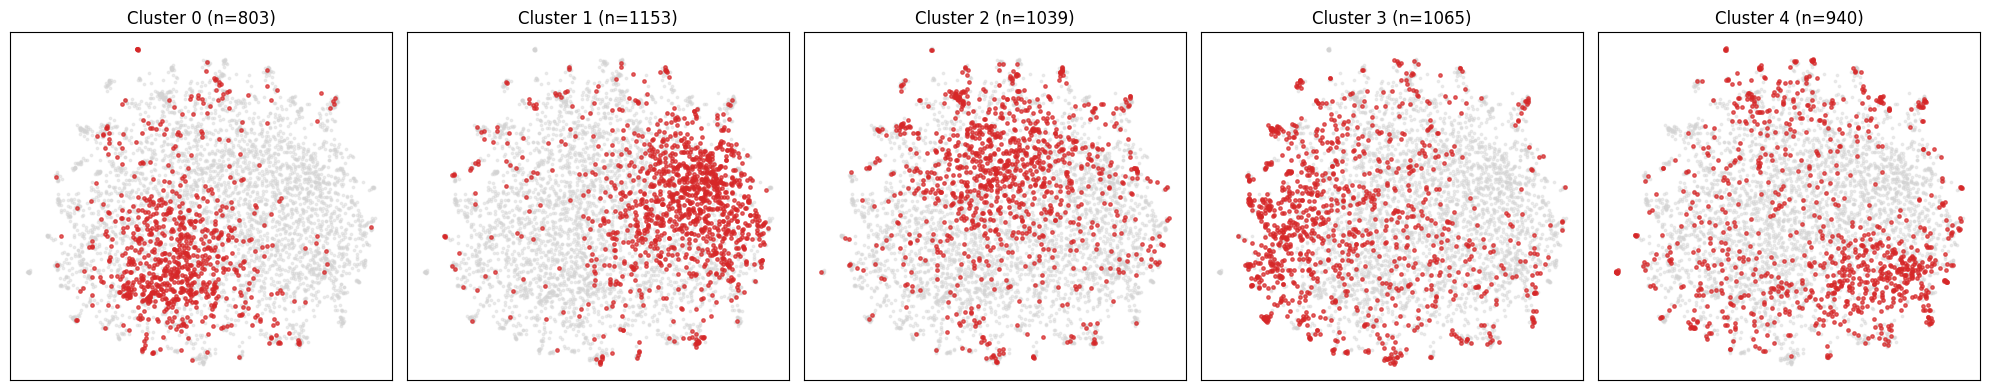

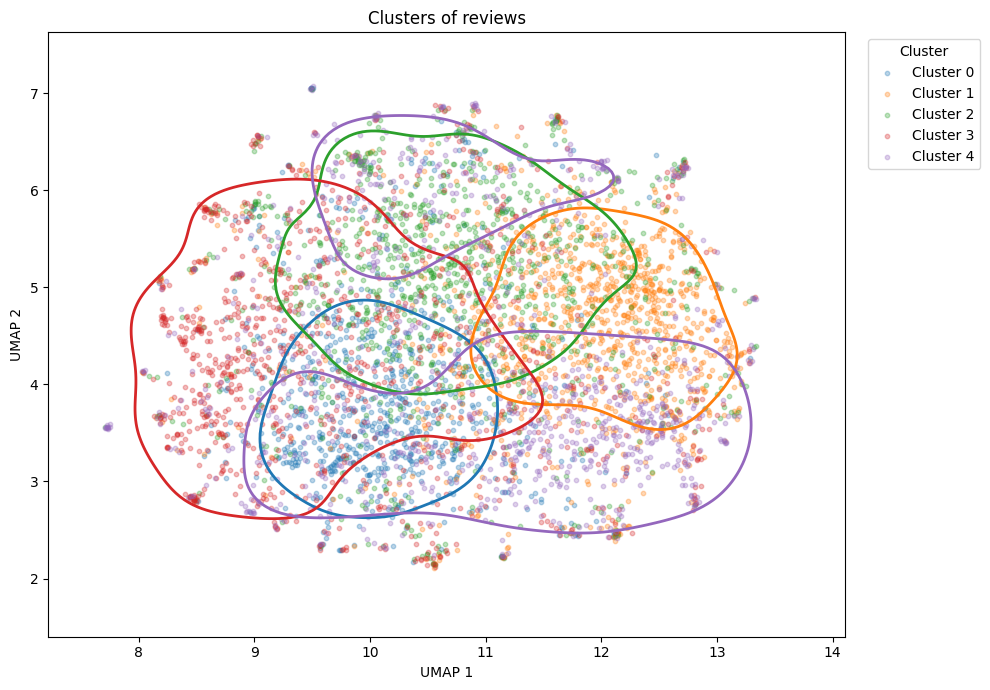

In [ ]:
plot_clusters(points_2d, W_5.argmax(axis=1))

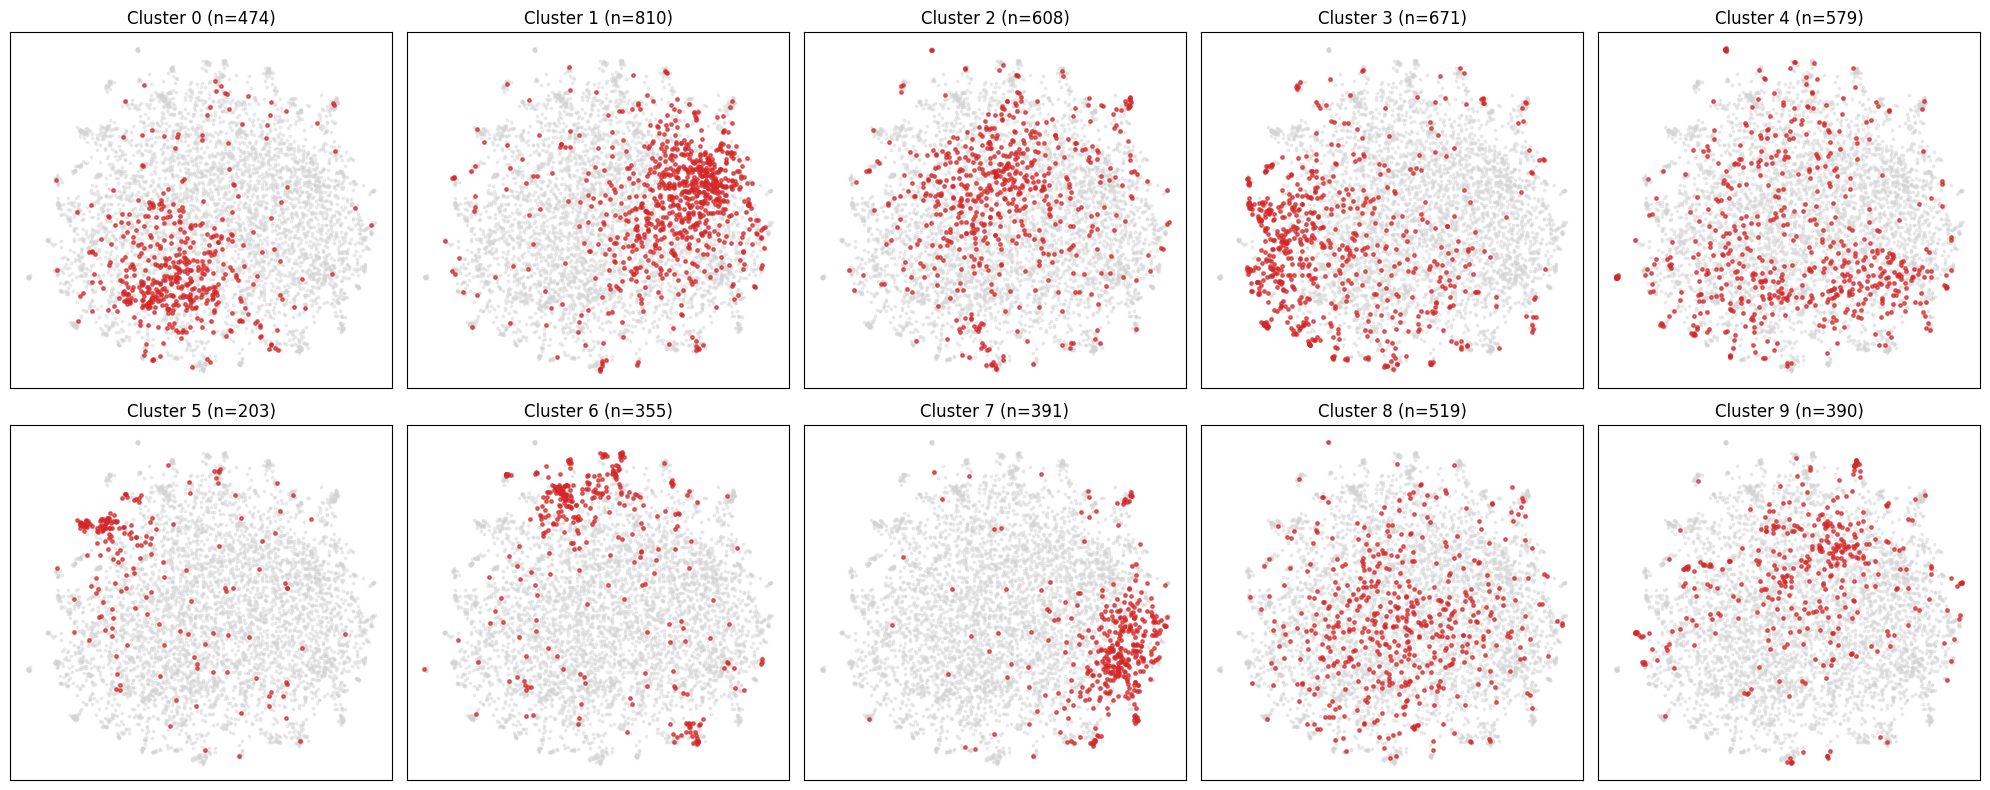

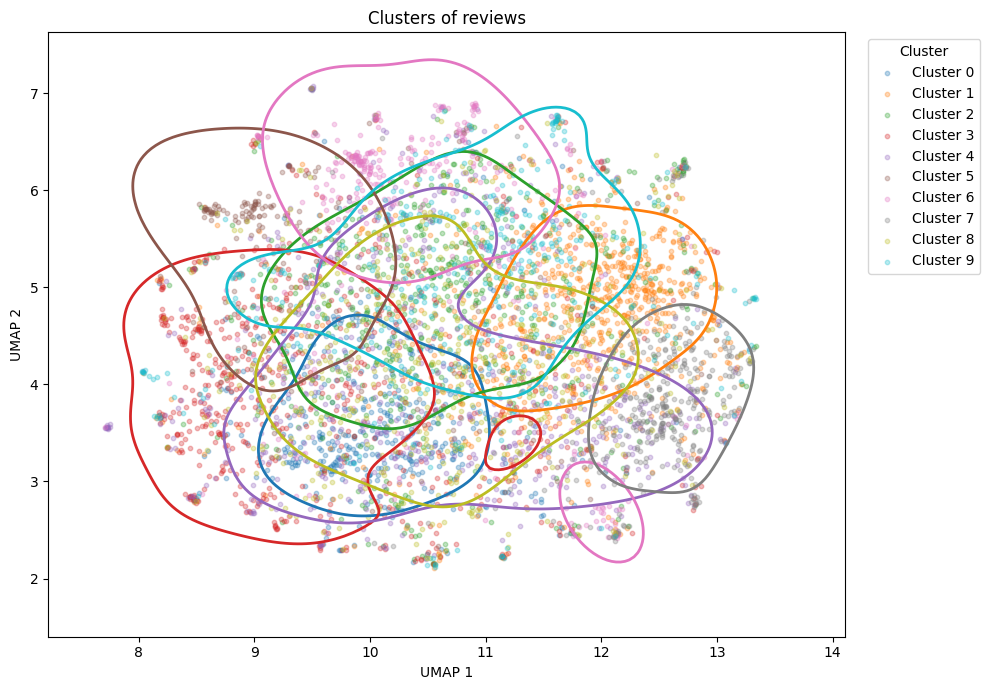

In [ ]:
plot_clusters(points_2d, W_10.argmax(axis=1))

In [ ]:
# External validation
ari_nmf_5 = adjusted_rand_score(
    raw_dataset.loc[:, "sentiment"], df_review_topic_5.loc[:, "dominant_topic"]
)
ari_nmf_10 = adjusted_rand_score(
    raw_dataset.loc[:, "sentiment"], df_review_topic_10.loc[:, "dominant_topic"]
)

nmi_nmf_5 = normalized_mutual_info_score(
    raw_dataset.loc[:, "sentiment"], df_review_topic_5.loc[:, "dominant_topic"]
)
nmi_nmf_10 = normalized_mutual_info_score(
    raw_dataset.loc[:, "sentiment"], df_review_topic_10.loc[:, "dominant_topic"]
)

homo_nmf_5, comp_nmf_5, v_measure_nmf_5 = homogeneity_completeness_v_measure(
    raw_dataset.loc[:, "sentiment"], df_review_topic_5.loc[:, "dominant_topic"]
)
homo_nmf_10, comp_nmf_10, v_measure_nmf_10 = homogeneity_completeness_v_measure(
    raw_dataset.loc[:, "sentiment"], df_review_topic_10.loc[:, "dominant_topic"]
)

ext_val_df_nmf = pd.DataFrame(
    {
        "Clusters": ["5", "10"],
        "Adjusted Rand Index": [ari_nmf_5, ari_nmf_10],
        "Normalized Mutual Information": [nmi_nmf_5, nmi_nmf_10],
        "Homogeneity": [homo_nmf_5, homo_nmf_10],
        "Completeness": [comp_nmf_5, comp_nmf_10],
        "V_Measure": [v_measure_nmf_5, v_measure_nmf_10],
    },
)

print(ext_val_df_nmf.to_string(index=False))

Clusters  Adjusted Rand Index  Normalized Mutual Information  Homogeneity  Completeness  V_Measure
       5             0.119242                       0.125043     0.206639      0.089645   0.125043
      10             0.068490                       0.085495     0.179806      0.056080   0.085495


## Evaluation & model comparison

Describe how you compare the methods and why. (approx. two or three paragraphs)

## Team member contributions

*   Ossama Sijbesma: data description, pre-processing, text representation, text clustering
*   Nóra Zala: NMF topic modeling, pre-processing, model descriptions